# Task 5: Autocomplete and Autocorrect Data Analytics

## 1. Project Overview

This project analyses autocomplete and autocorrect techniques using Natural Language Processing (NLP). It uses text data from the Enron Email Dataset to build word prediction and spelling correction systems.

### Objectives
- Preprocess text using NLP techniques.
- Build frequency-based bigram and trigram autocomplete models.
- Test autocomplete predictions using at least 10 prefixes.
- Implement and compare two autocorrect approaches.
- Evaluate precision, recall, and correction accuracy.
- Visualize word frequencies and autocorrect performance.
- Discuss the limitations of these approaches compared with Google Keyboard.

In [1]:
%pip install pandas numpy nltk matplotlib seaborn scikit-learn pyspellchecker

Note: you may need to restart the kernel to use updated packages.


## 2. Import Libraries

Import the Python libraries required for data handling, text preprocessing, autocomplete, spelling correction, evaluation, and visualization.

In [2]:
import os
import re
import string
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from spellchecker import SpellChecker

from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

print("All libraries imported successfully!")

All libraries imported successfully!


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hi\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hi\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 3. Load the Dataset

Load the Enron Email Dataset from the `data` folder. Inspect its dimensions, column names, and sample records before preprocessing the text.

In [3]:
# Define project paths
DATA_PATH = r"C:\users\hi\Documents\OIBSIP\Autocomplete-Autocorrect-Analysis\ data\emails.csv"

OUTPUT_DIR = "output"
SCREENSHOT_DIR = "screenshots"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(SCREENSHOT_DIR, exist_ok=True)

# Check whether the dataset exists
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Check the CSV file path."
    )

# Load the dataset
df = pd.read_csv(
    DATA_PATH,
    usecols=["message"],
    nrows=50000,
    on_bad_lines="skip"
)

# Remove empty messages
df = df.dropna(subset=["message"]).copy()
df["message"] = df["message"].astype(str)
df = df[df["message"].str.strip() != ""]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 3 email messages:")
display(df.head(3))

Dataset loaded successfully!
Dataset shape: (50000, 1)

Column names:
['message']

First 3 email messages:


,message
0,Message-ID: <18782981.1075855378110.JavaMail.e...
1,Message-ID: <15464986.1075855378456.JavaMail.e...
2,Message-ID: <24216240.1075855687451.JavaMail.e...


## 4. Initial Dataset Inspection

Inspect the dataset for missing values, duplicate messages, and message lengths. This helps us understand the quality and structure of the text before applying NLP preprocessing.

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   message  50000 non-null  str  
dtypes: str(1)
memory usage: 123.9 MB

Missing values:
message    0
dtype: int64

Duplicate messages: 0

Message length statistics:


count     50000.000000
mean       2590.313420
std        5039.868934
min         395.000000
25%         880.000000
50%        1474.000000
75%        2685.000000
max      272782.000000
Name: message_length, dtype: float64

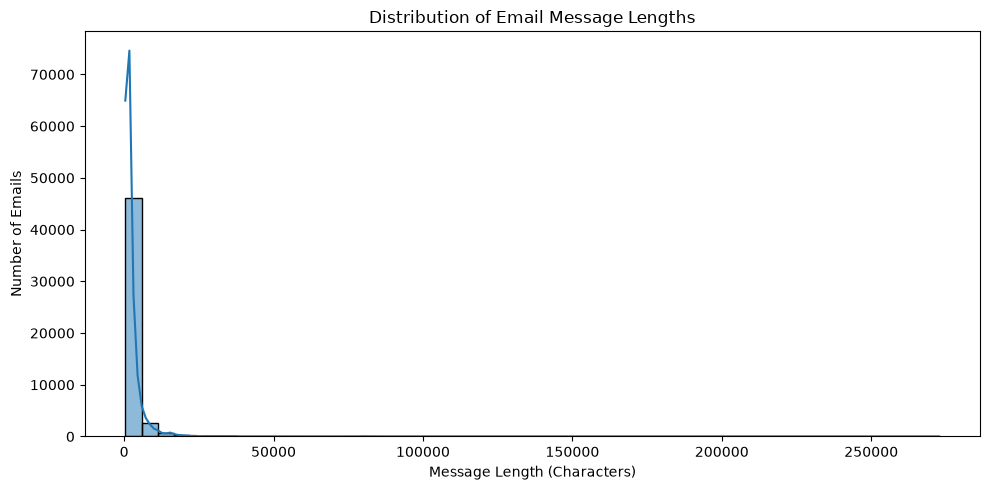

In [4]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate messages:", df["message"].duplicated().sum())

df["message_length"] = df["message"].str.len()

print("\nMessage length statistics:")
display(df["message_length"].describe())

# Visualize message lengths
plt.figure(figsize=(10, 5))
sns.histplot(df["message_length"], bins=50, kde=True)
plt.title("Distribution of Email Message Lengths")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Number of Emails")
plt.tight_layout()
plt.show()

### Initial Analysis

The dataset inspection identifies the number of available email messages, missing or duplicate records, and the variation in message lengths. Email text may contain signatures, quoted replies, and formatting noise, which should be considered during preprocessing.

## 5. Text Cleaning and NLP Preprocessing

Natural Language Processing (NLP) preprocessing converts raw email messages into clean, consistent text. Email messages may contain HTML, URLs, email addresses, punctuation, numbers, and other noise.

In this step, we will:
- Convert text to lowercase.
- Remove URLs, email addresses, and HTML tags.
- Remove punctuation and numbers.
- Tokenize the text into individual words.
- Remove English stopwords.
- Retain useful words for autocomplete and autocorrect analysis.

In [5]:
import os
import pandas as pd
import re
import nltk
from collections import Counter

print("Current folder:", os.getcwd())

if "df" not in globals():
    print("Dataset is not loaded. Please run your dataset-loading cell first.")
else:
    print("DataFrame shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(2))

Current folder: C:\Users\hi\Documents\OIBSIP\Autocomplete-Autocorrect-Analysis
DataFrame shape: (50000, 2)
Columns: ['message', 'message_length']
                                             message  message_length
0  Message-ID: <18782981.1075855378110.JavaMail.e...             492
1  Message-ID: <15464986.1075855378456.JavaMail.e...            1276


In [6]:
# Download stopwords if needed
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

# Verify the required column exists
if "message" not in df.columns:
    raise ValueError(
        f"'message' column not found. Available columns: {df.columns.tolist()}"
    )

# Keep valid, unique messages
df = df.dropna(subset=["message"]).copy()
df["message"] = df["message"].astype(str)
df = df[df["message"].str.strip() != ""]
df = df.drop_duplicates(subset=["message"]).head(5000).copy()

def clean_text(text):
    text = str(text).lower()

    # Remove URLs, email addresses, and HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"<[^>]*>", " ", text)

    # Keep alphabetic words only
    tokens = re.findall(r"[a-z]+", text)

    # Remove stopwords and one-letter words
    return [
        word for word in tokens
        if len(word) > 1 and word not in stop_words
    ]

print("Processing messages...")

df["tokens"] = df["message"].map(clean_text)

# Remove messages with no usable words
df = df[df["tokens"].map(len) > 0].copy()

print("\nPreprocessing completed successfully!")
print("Messages processed:", len(df))
print("Total tokens:", sum(len(tokens) for tokens in df["tokens"]))

display(df[["message", "tokens"]].head(3))

Processing messages...

Preprocessing completed successfully!
Messages processed: 5000
Total tokens: 686782


,message,tokens
0,Message-ID: <18782981.1075855378110.JavaMail.e...,"[message, id, date, mon, may, pdt, subject, mi..."
1,Message-ID: <15464986.1075855378456.JavaMail.e...,"[message, id, date, fri, may, pdt, subject, mi..."
2,Message-ID: <24216240.1075855687451.JavaMail.e...,"[message, id, date, wed, oct, pdt, subject, te..."


## 6. Word Frequency Analysis

Word frequency analysis identifies the most common words in the cleaned email corpus. These frequencies help us understand the vocabulary and build a frequency-based autocomplete model.

,Word,Frequency
0,allen,10811
1,content,10140
2,phillip,9705
3,subject,8839
4,cc,8462
5,john,7186
6,arnold,6463
7,message,6335
8,us,5802
9,date,5605


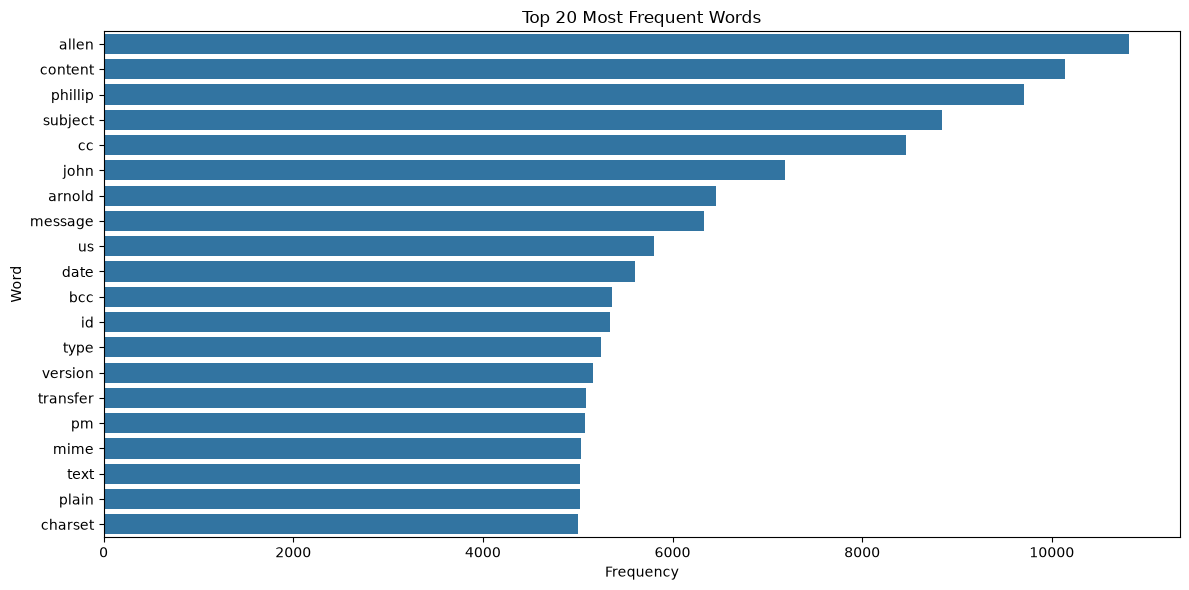

In [21]:
# Combine all processed tokens
all_tokens = [
    word
    for tokens in df["tokens"]
    for word in tokens
]

word_freq = Counter(all_tokens)

# Create a DataFrame of the top 20 words
frequency_df = pd.DataFrame(
    word_freq.most_common(20),
    columns=["Word", "Frequency"]
)

display(frequency_df)

# Plot the top 20 words
plt.figure(figsize=(12, 6))
sns.barplot(data=frequency_df, x="Frequency", y="Word")

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "top_20_word_frequency.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns


### Word Frequency Analysis

The bar chart shows the 20 most frequent words in the cleaned email corpus. Frequently occurring words can provide useful candidates for autocomplete suggestions. However, frequent words do not always represent the most suitable continuation of a sentence.

## 7. Bigram-Based Autocomplete

A bigram model predicts the next word using the immediately preceding word. It counts consecutive word pairs and selects the most frequent continuations as suggestions.

In [10]:
from collections import defaultdict, Counter

bigram_counts = defaultdict(Counter)

for tokens in df["tokens"]:
    for i in range(len(tokens) - 1):
        bigram_counts[tokens[i]][tokens[i + 1]] += 1

def predict_bigram(prefix, top_n=3):
    prefix = prefix.lower().strip()

    if prefix not in bigram_counts:
        return []

    return [
        word for word, count
        in bigram_counts[prefix].most_common(top_n)
    ]

# Test at least 10 prefixes
test_prefixes = [
    "thank", "please", "meeting", "project", "business",
    "market", "report", "company", "energy", "information"
]

bigram_results = []

for prefix in test_prefixes:
    predictions = predict_bigram(prefix, top_n=3)

    bigram_results.append({
        "Prefix": prefix,
        "Prediction 1": predictions[0] if len(predictions) > 0 else "No prediction",
        "Prediction 2": predictions[1] if len(predictions) > 1 else "",
        "Prediction 3": predictions[2] if len(predictions) > 2 else ""
    })

bigram_results_df = pd.DataFrame(bigram_results)
display(bigram_results_df)

,Prefix,Prediction 1,Prediction 2,Prediction 3
0,thank,phillip,jeff,help
1,please,respond,let,contact
2,meeting,mime,dates,meeting
3,project,would,fails,needs
4,business,development,units,opportunities
5,market,analysis,monitoring,prices
6,report,mime,edison,name
7,company,inc,current,worth
8,energy,trading,insight,services
9,information,contained,received,please


### Bigram Model Analysis

The bigram model suggests up to three words based on the frequency of word pairs in the corpus. Its predictions are simple and efficient, but they do not consider the full sentence context. Prefixes absent from the training corpus may not receive any suggestions.

## 8. Trigram-Based Autocomplete

A trigram model predicts the next word based on the previous two words. Using two preceding words provides more context than the bigram model.

In [11]:
trigram_counts = defaultdict(Counter)

for tokens in df["tokens"]:
    for i in range(len(tokens) - 2):
        prefix = (tokens[i], tokens[i + 1])
        next_word = tokens[i + 2]
        trigram_counts[prefix][next_word] += 1

def predict_trigram(prefix, top_n=3):
    words = prefix.lower().split()

    if len(words) < 2:
        return []

    key = (words[-2], words[-1])

    if key not in trigram_counts:
        return []

    return [
        word for word, count
        in trigram_counts[key].most_common(top_n)
    ]

test_trigram_prefixes = [
    "thank you",
    "please let",
    "look forward",
    "project status",
    "new york",
    "energy market",
    "meeting schedule",
    "business plan",
    "power plant",
    "customer service"
]

trigram_results = []

for prefix in test_trigram_prefixes:
    predictions = predict_trigram(prefix, top_n=3)

    trigram_results.append({
        "Prefix": prefix,
        "Prediction 1": predictions[0] if len(predictions) > 0 else "No prediction",
        "Prediction 2": predictions[1] if len(predictions) > 1 else "",
        "Prediction 3": predictions[2] if len(predictions) > 2 else ""
    })

trigram_results_df = pd.DataFrame(trigram_results)
display(trigram_results_df)

,Prefix,Prediction 1,Prediction 2,Prediction 3
0,thank you,No prediction,,
1,please let,know,us,group
2,look forward,working,hearing,seeing
3,project status,No prediction,,
4,new york,times,zone,city
5,energy market,said,,
6,meeting schedule,doc,reversed,
7,business plan,meetings,workshops,market
8,power plant,chula,maintenance,unit
9,customer service,department,staying,survey


### Trigram Model Analysis

The trigram model uses more context to generate predictions. It may distinguish between different phrases that share the same final word. However, two-word prefixes can be less common, causing the model to return fewer suggestions for unseen combinations.

## 9. Comparison of Bigram and Trigram Models

This section compares the number of test prefixes for which each model produces at least one prediction. Prediction coverage indicates how often a model can provide a suggestion, but it does not measure whether the suggestion is correct.

,Model,Prefixes with predictions,Total test prefixes,Coverage (%)
0,Bigram,10,10,100.0
1,Trigram,8,10,80.0


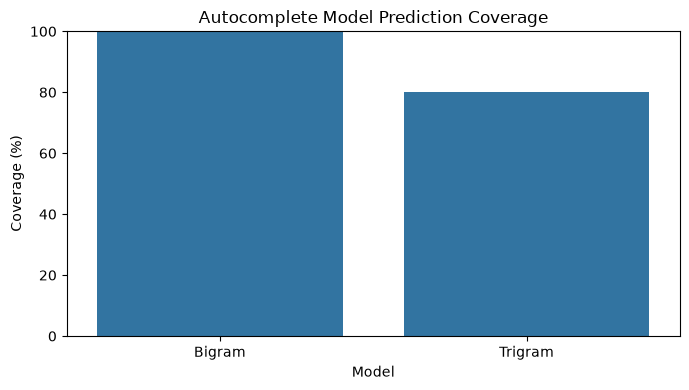

In [12]:
bigram_coverage = sum(
    bool(predict_bigram(prefix))
    for prefix in test_prefixes
)

trigram_coverage = sum(
    bool(predict_trigram(prefix))
    for prefix in test_trigram_prefixes
)

coverage_df = pd.DataFrame({
    "Model": ["Bigram", "Trigram"],
    "Prefixes with predictions": [
        bigram_coverage,
        trigram_coverage
    ],
    "Total test prefixes": [
        len(test_prefixes),
        len(test_trigram_prefixes)
    ]
})

coverage_df["Coverage (%)"] = (
    coverage_df["Prefixes with predictions"]
    / coverage_df["Total test prefixes"] * 100
).round(2)

display(coverage_df)

plt.figure(figsize=(7, 4))
sns.barplot(
    data=coverage_df,
    x="Model",
    y="Coverage (%)"
)

plt.title("Autocomplete Model Prediction Coverage")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "autocomplete_coverage.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Model Comparison Analysis

Prediction coverage shows how frequently each model finds suggestions for the selected prefixes. The trigram model may provide more context-specific suggestions but may have lower coverage. Coverage alone cannot establish which model is more accurate; that requires testing predictions against actual next words from held-out text.

## 10. Autocomplete Evaluation Using Training and Test Data

To evaluate autocomplete fairly, we split the email messages into training and testing sets. The training set builds the prediction model, while the testing set provides actual next words to check whether the model's suggestions are correct.

We will measure Precision@3 and Recall@3 using test prefixes with a known next word.

In [13]:
import random
from collections import defaultdict, Counter

# Use the original text so word order and stopwords are preserved
def tokenize_for_prediction(text):
    return re.findall(r"[a-z]+", str(text).lower())

# Split messages into training and testing sets
messages = (
    df["message"]
    .dropna()
    .astype(str)
    .drop_duplicates()
    .tolist()
)

random.seed(42)
random.shuffle(messages)

split_index = int(len(messages) * 0.8)
train_messages = messages[:split_index]
test_messages = messages[split_index:]

# Build models from training messages only
eval_bigram = defaultdict(Counter)
eval_trigram = defaultdict(Counter)

for message in train_messages:
    words = tokenize_for_prediction(message)

    for i in range(len(words) - 1):
        eval_bigram[words[i]][words[i + 1]] += 1

    for i in range(len(words) - 2):
        eval_trigram[(words[i], words[i + 1])][words[i + 2]] += 1

def get_bigram_predictions(prefix, top_n=3):
    return [
        word for word, count
        in eval_bigram[prefix].most_common(top_n)
    ]

def get_trigram_predictions(prefix, top_n=3):
    return [
        word for word, count
        in eval_trigram[prefix].most_common(top_n)
    ]

print("Training messages:", len(train_messages))
print("Testing messages:", len(test_messages))
print("Evaluation models are ready.")

Training messages: 4000
Testing messages: 1000
Evaluation models are ready.


## 11. Autocomplete Precision and Recall

Precision@3 measures the proportion of the three suggested words that match the actual next word. Recall@3 measures whether the actual next word appears among the three suggestions.

We evaluate both bigram and trigram models on contexts taken from held-out messages. This provides a more meaningful comparison than checking prediction coverage alone.

In [14]:
def evaluate_autocomplete(test_messages, max_examples=1000):
    results = []

    for message in test_messages:
        words = tokenize_for_prediction(message)

        # Bigram: one previous word
        for i in range(1, len(words)):
            prefix = words[i - 1]
            actual = words[i]
            predictions = get_bigram_predictions(prefix, 3)

            if predictions:
                hit = int(actual in predictions)

                results.append({
                    "Model": "Bigram",
                    "Prefix": prefix,
                    "Actual Next Word": actual,
                    "Predictions": ", ".join(predictions),
                    "Hit": hit,
                    "Precision@3": hit / 3,
                    "Recall@3": hit
                })

            if len(results) >= max_examples:
                break

        if len(results) >= max_examples:
            break

    # Evaluate trigram separately
    trigram_results = []

    for message in test_messages:
        words = tokenize_for_prediction(message)

        for i in range(2, len(words)):
            prefix = (words[i - 2], words[i - 1])
            actual = words[i]
            predictions = get_trigram_predictions(prefix, 3)

            if predictions:
                hit = int(actual in predictions)

                trigram_results.append({
                    "Model": "Trigram",
                    "Prefix": " ".join(prefix),
                    "Actual Next Word": actual,
                    "Predictions": ", ".join(predictions),
                    "Hit": hit,
                    "Precision@3": hit / 3,
                    "Recall@3": hit
                })

            if len(trigram_results) >= max_examples:
                break

        if len(trigram_results) >= max_examples:
            break

    return pd.DataFrame(results), pd.DataFrame(trigram_results)

bigram_eval_df, trigram_eval_df = evaluate_autocomplete(
    test_messages,
    max_examples=1000
)

eval_df = pd.concat(
    [bigram_eval_df, trigram_eval_df],
    ignore_index=True
)

if eval_df.empty:
    print("No test contexts with predictions were found.")
else:
    metrics_df = (
        eval_df.groupby("Model")
        .agg(
            Evaluated_Contexts=("Hit", "count"),
            Precision_at_3=("Precision@3", "mean"),
            Recall_at_3=("Recall@3", "mean"),
            Hit_Rate=("Hit", "mean")
        )
        .reset_index()
    )

    metrics_df[
        ["Precision_at_3", "Recall_at_3", "Hit_Rate"]
    ] = metrics_df[
        ["Precision_at_3", "Recall_at_3", "Hit_Rate"]
    ].round(4)

    display(metrics_df)
    display(eval_df.head(10))

    eval_df.to_csv(
        os.path.join(OUTPUT_DIR, "autocomplete_evaluation.csv"),
        index=False
    )

,Model,Evaluated_Contexts,Precision_at_3,Recall_at_3,Hit_Rate
0,Bigram,1000,0.189,0.567,0.567
1,Trigram,1000,0.272,0.816,0.816


,Model,Prefix,Actual Next Word,Predictions,Hit,Precision@3,Recall@3
0,Bigram,message,id,"id, from, is",1,0.333333,1
1,Bigram,id,javamail,"javamail, pallen, request",1,0.333333,1
2,Bigram,javamail,evans,evans,1,0.333333,1
3,Bigram,evans,thyme,"thyme, e, i",1,0.333333,1
4,Bigram,thyme,date,date,1,0.333333,1
5,Bigram,date,thu,"wed, mon, tue",0,0.000000,0
6,Bigram,thu,mar,"mar, dec, aug",1,0.333333,1
7,Bigram,mar,pst,"pst, apr, cal",1,0.333333,1
8,Bigram,pst,from,"from, original, image",1,0.333333,1
9,Bigram,from,phillip,"phillip, john, the",1,0.333333,1


### Autocomplete Evaluation Analysis

Precision@3 and Recall@3 evaluate whether the actual next word appears among the model's top three suggestions. A higher score indicates better performance on the evaluated contexts.

The results depend on the email corpus, the frequency of each prefix, and the selected test sample. This is a basic next-word evaluation rather than a complete measure of real-world keyboard quality.

## 12. Autocorrect Using Two Approaches

Autocorrect identifies misspelled words and suggests possible corrections. In this project, we compare a dictionary-based spellchecker with a custom approach that selects similar words from the training corpus vocabulary.

Both approaches will be tested on the same set of deliberately misspelled words. Their correction accuracy will be compared against the expected correct spellings.

In [15]:
from spellchecker import SpellChecker
from difflib import get_close_matches

# Approach 1: pyspellchecker
spell = SpellChecker()

def autocorrect_spellchecker(word):
    return spell.correction(word) or word

# Build vocabulary from original training text
vocab_counter = Counter()

for message in train_messages:
    vocab_counter.update(tokenize_for_prediction(message))

# Use frequent corpus words as candidates
vocabulary = [
    word for word, count in vocab_counter.most_common(20000)
    if len(word) > 1
]

# Approach 2: Similarity matching using difflib
def autocorrect_edit_distance(word):
    word = word.lower()

    matches = get_close_matches(
        word,
        vocabulary,
        n=1,
        cutoff=0.75
    )

    return matches[0] if matches else word

print("Autocorrect approaches are ready.")
print("Vocabulary size:", len(vocabulary))
print("Example 1:", autocorrect_spellchecker("recieve"))
print("Example 2:", autocorrect_edit_distance("recieve"))

Autocorrect approaches are ready.
Vocabulary size: 19974
Example 1: receive
Example 2: recieve


## 13. Autocorrect Testing and Accuracy

We use a fixed test list of deliberately misspelled words with their expected correct spellings. A prediction is considered correct only when the suggested word exactly matches the expected spelling.

Correction accuracy is calculated as the percentage of test words corrected successfully.

In [16]:
# Test cases: misspelled word -> expected correct spelling
test_words = {
    "recieve": "receive",
    "definately": "definitely",
    "accomodate": "accommodate",
    "seperate": "separate",
    "occured": "occurred",
    "untill": "until",
    "wich": "which",
    "becuase": "because",
    "thier": "their",
    "adress": "address",
    "enviroment": "environment",
    "goverment": "government",
    "langauge": "language",
    "freind": "friend",
    "acheive": "achieve",
    "begining": "beginning",
    "sucessful": "successful",
    "tomorow": "tomorrow",
    "embarass": "embarrass",
    "wierd": "weird",
    "reccomend": "recommend",
    "responsibile": "responsible",
    "occassion": "occasion",
    "publically": "publicly",
    "buisness": "business"
}

autocorrect_results = []

for wrong, expected in test_words.items():
    suggestion1 = autocorrect_spellchecker(wrong)
    suggestion2 = autocorrect_edit_distance(wrong)

    autocorrect_results.append({
        "Misspelled Word": wrong,
        "Expected Word": expected,
        "SpellChecker Suggestion": suggestion1,
        "SpellChecker Correct": suggestion1 == expected,
        "EditDistance Suggestion": suggestion2,
        "EditDistance Correct": suggestion2 == expected
    })

autocorrect_df = pd.DataFrame(autocorrect_results)

display(autocorrect_df)

# Calculate accuracy
accuracy_spellchecker = autocorrect_df["SpellChecker Correct"].mean() * 100
accuracy_edit_distance = autocorrect_df["EditDistance Correct"].mean() * 100

accuracy_df = pd.DataFrame({
    "Approach": ["pyspellchecker", "difflib similarity matching"],
    "Correct Predictions": [
        autocorrect_df["SpellChecker Correct"].sum(),
        autocorrect_df["EditDistance Correct"].sum()
    ],
    "Total Test Words": [len(test_words), len(test_words)],
    "Accuracy (%)": [
        round(accuracy_spellchecker, 2),
        round(accuracy_edit_distance, 2)
    ]
})

display(accuracy_df)

autocorrect_df.to_csv(
    os.path.join(OUTPUT_DIR, "autocorrect_results.csv"),
    index=False
)

,Misspelled Word,Expected Word,SpellChecker Suggestion,SpellChecker Correct,EditDistance Suggestion,EditDistance Correct
0,recieve,receive,receive,True,recieve,False
1,definately,definitely,definitely,True,definitely,True
2,accomodate,accommodate,accommodate,True,accomodate,False
3,seperate,separate,separate,True,separate,True
4,occured,occurred,occurred,True,occured,False
5,untill,until,until,True,untill,False
6,wich,which,with,False,which,True
7,becuase,because,because,True,becuase,False
8,thier,their,their,True,tier,False
9,adress,address,dress,False,address,True


,Approach,Correct Predictions,Total Test Words,Accuracy (%)
0,pyspellchecker,23,25,92.0
1,difflib similarity matching,15,25,60.0


## 14. Autocorrect Performance Visualization

Compare the correction accuracy of both approaches. Also examine whether each test word was incorrect before correction and whether the resulting suggestion matches the expected spelling.

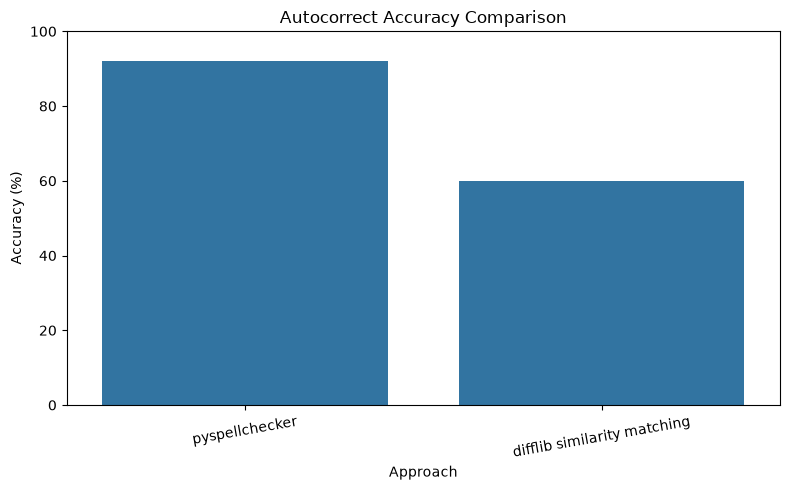

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=accuracy_df,
    x="Approach",
    y="Accuracy (%)"
)

plt.title("Autocorrect Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Approach")
plt.ylim(0, 100)
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "autocorrect_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

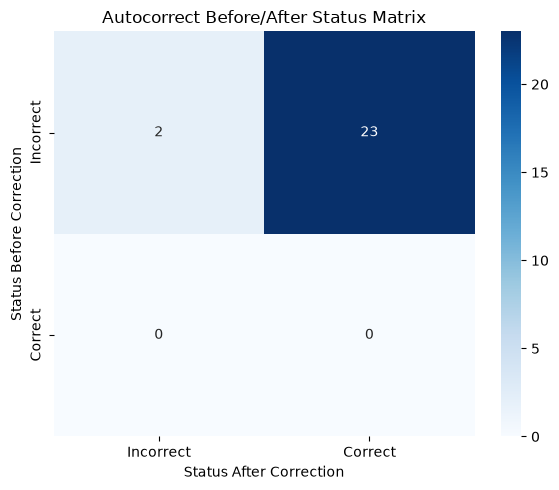

In [18]:
# Use pyspellchecker results for this transition matrix
before_status = [
    "Incorrect" if wrong != expected else "Correct"
    for wrong, expected in zip(
        autocorrect_df["Misspelled Word"],
        autocorrect_df["Expected Word"]
    )
]

after_status = [
    "Correct" if matches else "Incorrect"
    for matches in autocorrect_df["SpellChecker Correct"]
]

status_labels = ["Incorrect", "Correct"]

transition_matrix = confusion_matrix(
    before_status,
    after_status,
    labels=status_labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    transition_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=status_labels,
    yticklabels=status_labels
)

plt.title("Autocorrect Before/After Status Matrix")
plt.xlabel("Status After Correction")
plt.ylabel("Status Before Correction")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "autocorrect_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Autocorrect Analysis

The accuracy comparison shows how often each approach produces the expected spelling. The dictionary-based approach uses its built-in vocabulary, while the custom similarity approach depends on the words available in the email corpus.

Neither approach is guaranteed to select the correct word in every case. The custom approach may suggest a similar but contextually incorrect word, and the dictionary-based approach may struggle with names, technical terms, or words missing from its dictionary.

## 15. Exporting Project Results

Save the main analysis tables and visualizations in the output folder so that the results can be reviewed and included in the project repository.

In [20]:
import os
import pandas as pd
from collections import Counter

# Create output folder
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Save bigram predictions if available
if "bigram_results_df" in globals():
    bigram_results_df.to_csv(
        os.path.join(OUTPUT_DIR, "bigram_predictions.csv"),
        index=False
    )
    print("Saved bigram predictions.")

# 2. Save trigram predictions if available
if "trigram_results_df" in globals():
    trigram_results_df.to_csv(
        os.path.join(OUTPUT_DIR, "trigram_predictions.csv"),
        index=False
    )
    print("Saved trigram predictions.")

# 3. Recreate and save word frequencies
if "df" in globals() and "tokens" in df.columns:
    all_tokens = [
        word
        for tokens in df["tokens"]
        for word in tokens
    ]

    word_freq = Counter(all_tokens)

    frequency_df = pd.DataFrame(
        word_freq.most_common(20),
        columns=["Word", "Frequency"]
    )

    frequency_df.to_csv(
        os.path.join(OUTPUT_DIR, "top_20_word_frequency.csv"),
        index=False
    )
    print("Saved top 20 word frequencies.")
else:
    print("Cannot create word frequencies: run the preprocessing cell first.")

# 4. Save evaluation metrics if available
if "metrics_df" in globals():
    metrics_df.to_csv(
        os.path.join(OUTPUT_DIR, "autocomplete_metrics.csv"),
        index=False
    )
    print("Saved autocomplete metrics.")

# 5. Save autocorrect results if available
if "autocorrect_df" in globals():
    autocorrect_df.to_csv(
        os.path.join(OUTPUT_DIR, "autocorrect_results.csv"),
        index=False
    )
    print("Saved autocorrect results.")

# 6. Verify output files
print("\nFiles currently in the output folder:")
for file in sorted(os.listdir(OUTPUT_DIR)):
    print("-", file)

Saved bigram predictions.
Saved trigram predictions.
Saved top 20 word frequencies.
Saved autocomplete metrics.
Saved autocorrect results.

Files currently in the output folder:
- autocomplete_coverage.png
- autocomplete_evaluation.csv
- autocomplete_metrics.csv
- autocorrect_accuracy.png
- autocorrect_confusion_matrix.png
- autocorrect_results.csv
- bigram_predictions.csv
- top_20_word_frequency.csv
- trigram_predictions.csv


## 16. Limitations

- **Limited context:** Bigram and trigram models use only one or two preceding words.
- **Unseen phrases:** The models may not predict words for prefixes that do not occur in the training corpus.
- **Email-specific language:** The Enron corpus contains business vocabulary and email formatting that may not represent general typing.
- **Dictionary limitations:** A spellchecker may struggle with names, abbreviations, and technical terms.
- **Vocabulary dependence:** The custom similarity approach can only select candidates from its vocabulary.
- **No sentence-level understanding:** Similarity-based corrections may be grammatically or contextually inappropriate.
- **Difference from modern keyboards:** Google Keyboard and similar systems may use larger datasets, contextual language models, personalization, and real-time learning.

## 17. Conclusion

This project demonstrates how NLP preprocessing, n-gram frequency models, dictionary-based spelling correction, and similarity matching can be used to develop basic autocomplete and autocorrect systems.

The evaluation metrics and visualizations help compare the approaches on the selected datasets. The results also demonstrate why context, vocabulary coverage, and realistic testing are important for building reliable text prediction systems.